In [1]:
'''Evaluate regression models by calculating RMSE, MAE, and R-squared metrics, performing residual diagnostics, 
and validating predictive accuracy across different subpopulations and temporal splits.'''

'Evaluate regression models by calculating RMSE, MAE, and R-squared metrics, performing residual diagnostics, \nand validating predictive accuracy across different subpopulations and temporal splits.'

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [3]:
df = pd.read_csv("global_pharmacy_sales_data.csv")

print("dataset shape:", df.shape)

display(df.head())

print("\ncolumn information:")
df.info()

print("\nmissing values:")
display(df.isnull().sum())

print("\nduplicate records:", df.duplicated().sum())

dataset shape: (177990, 14)


,date,year,month,day,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag
0,2025-10-12,2025,10,12,Middle East,UAE,Chronic,Amlodipine,0-12,328,45.38,4774,466,0
1,2020-09-15,2020,9,15,South Asia,India,Chronic,Amlodipine,26-45,371,75.49,4584,181,1
2,2020-02-26,2020,2,26,Middle East,UAE,Vitamin,Vitamin C,0-12,948,22.51,3934,556,1
3,2025-11-09,2025,11,9,South Asia,Sri Lanka,Chronic,Amlodipine,0-12,275,63.29,4544,330,0
4,2022-04-04,2022,4,4,South America,Argentina,Chronic,Amlodipine,26-45,563,44.28,4284,590,0



column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 177990 entries, 0 to 177989
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   date                   177990 non-null  object 
 1   year                   177990 non-null  int64  
 2   month                  177990 non-null  int64  
 3   day                    177990 non-null  int64  
 4   region                 177990 non-null  object 
 5   country                177990 non-null  object 
 6   category               177990 non-null  object 
 7   medicine               177990 non-null  object 
 8   age_group              177990 non-null  object 
 9   units_sold             177990 non-null  int64  
 10  unit_price             177990 non-null  float64
 11  stock_level            177990 non-null  int64  
 12  expiry_days_remaining  177990 non-null  int64  
 13  covid_flag             177990 non-null  int64  
dtypes: float64(1), 

date                     0
year                     0
month                    0
day                      0
region                   0
country                  0
category                 0
medicine                 0
age_group                0
units_sold               0
unit_price               0
stock_level              0
expiry_days_remaining    0
covid_flag               0
dtype: int64


duplicate records: 2630


In [4]:
#Data preparation
# remove duplicate records
df = df.drop_duplicates().copy()
# identify and convert date columns
date_columns = [
    col for col in df.columns
    if "date" in col.lower()
]

for col in date_columns:
    df[col] = pd.to_datetime(df[col], errors="coerce")

# select a date column for temporal validation
available_dates = [
    col for col in date_columns
    if df[col].notna().any()
]

if not available_dates:
    raise ValueError("a valid date column is required for temporal validation")

date_column = available_dates[0]

# remove records without valid dates
df = df.dropna(subset=[date_column]).copy()

# create additional calendar features
df["calendar_year"] = df[date_column].dt.year
df["calendar_month"] = df[date_column].dt.month
df["day_of_week"] = df[date_column].dt.dayofweek

print("date column selected:", date_column)
print("prepared dataset shape:", df.shape)

date column selected: date
prepared dataset shape: (175360, 17)


In [5]:
#Select regression target dynamically
# identify numerical columns suitable for regression
numeric_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

print("available numerical target columns:")
for col in numeric_columns:
    print("-", col)

target = input(
    "\nenter target column (press enter for units_sold): "
).strip()

if not target:
    target = next(
        (col for col in numeric_columns
         if col.lower() == "units_sold"),
        numeric_columns[0]
    )

if target not in numeric_columns:
    raise ValueError("selected target must be a numerical column")

print("\nselected regression target:", target)

available numerical target columns:
- year
- month
- day
- units_sold
- unit_price
- stock_level
- expiry_days_remaining
- covid_flag
- calendar_year
- calendar_month
- day_of_week

selected regression target: units_sold


In [6]:
#Feature engineering and chronological splitting
# remove records with missing target values
df = df.dropna(subset=[target]).copy()

# sort records according to date
df = df.sort_values(date_column).reset_index(drop=True)

# remove the original date and target from predictors
X = df.drop(columns=[target] + date_columns)

y = df[target]

# identify numerical and categorical features
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# chronological 70:15:15 split
total = len(df)

train_end = int(total * 0.70)
validation_end = int(total * 0.85)

X_train = X.iloc[:train_end]
X_val = X.iloc[train_end:validation_end]
X_test = X.iloc[validation_end:]

y_train = y.iloc[:train_end]
y_val = y.iloc[train_end:validation_end]
y_test = y.iloc[validation_end:]

print("training records:", len(X_train))
print("validation records:", len(X_val))
print("testing records:", len(X_test))

print("\ntraining period:")
print(df[date_column].iloc[0], "to",
      df[date_column].iloc[train_end - 1])

print("\nvalidation period:")
print(df[date_column].iloc[train_end], "to",
      df[date_column].iloc[validation_end - 1])

print("\ntesting period:")
print(df[date_column].iloc[validation_end], "to",
      df[date_column].iloc[-1])

training records: 122751
validation records: 26305
testing records: 26304

training period:
2020-01-01 00:00:00 to 2024-03-14 00:00:00

validation period:
2024-03-14 00:00:00 to 2025-02-06 00:00:00

testing period:
2025-02-06 00:00:00 to 2025-12-31 00:00:00


In [7]:
#Build preprocessing pipeline
# numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=20
    ))
])

# combine preprocessing operations
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("preprocessing pipeline created")

preprocessing pipeline created


In [8]:
#Train multiple regression models
# define regression algorithms
models = {
    "Ridge Regression": Ridge(alpha=1.0),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}
validation_results = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("regressor", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_val)

    rmse = np.sqrt(mean_squared_error(y_val, predictions))
    mae = mean_absolute_error(y_val, predictions)
    r2 = r2_score(y_val, predictions)

    trained_models[name] = pipeline

    validation_results[name] = {
        "RMSE": rmse,
        "MAE": mae,
        "R2 Score": r2
    }

    print("\nmodel:", name)
    print("rmse:", round(rmse, 4))
    print("mae:", round(mae, 4))
    print("r2 score:", round(r2, 4))

validation_df = pd.DataFrame(
    validation_results
).T.sort_values("RMSE")

print("\nvalidation performance:")
display(validation_df)


model: Ridge Regression
rmse: 108.7624
mae: 93.9105
r2 score: 0.8025

model: Random Forest
rmse: 71.8603
mae: 57.7631
r2 score: 0.9138

model: Extra Trees
rmse: 72.0143
mae: 57.8037
r2 score: 0.9134

validation performance:


,RMSE,MAE,R2 Score
Random Forest,71.860332,57.763079,0.913788
Extra Trees,72.014330,57.803732,0.913418
Ridge Regression,108.762435,93.910502,0.802510


In [11]:
# select model with minimum validation rmse
best_model_name = validation_df["RMSE"].idxmin()

best_model = trained_models[best_model_name]

print("selected best model:", best_model_name)

# predict on unseen test data
test_predictions = best_model.predict(X_test)

# calculate evaluation metrics
test_rmse = np.sqrt(
    mean_squared_error(y_test, test_predictions)
)

test_mae = mean_absolute_error(
    y_test, test_predictions
)

test_r2 = r2_score(
    y_test, test_predictions
)

test_results = pd.DataFrame({
    "Metric": ["RMSE", "MAE", "R2 Score"],
    "Value": [test_rmse, test_mae, test_r2]
})

display(test_results)

print("final test evaluation completed")

selected best model: Random Forest


,Metric,Value
0,RMSE,72.946532
1,MAE,58.444157
2,R2 Score,0.916338


final test evaluation completed


In [12]:
#Compare all models on test data
test_comparison = []

for name, model in trained_models.items():

    predictions = model.predict(X_test)

    test_comparison.append({
        "Model": name,
        "RMSE": np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        "MAE": mean_absolute_error(
            y_test, predictions
        ),
        "R2 Score": r2_score(
            y_test, predictions
        )
    })

test_comparison_df = pd.DataFrame(test_comparison)

test_comparison_df = test_comparison_df.sort_values(
    "RMSE"
).reset_index(drop=True)

display(test_comparison_df)

,Model,RMSE,MAE,R2 Score
0,Extra Trees,72.899215,58.515511,0.916446
1,Random Forest,72.946532,58.444157,0.916338
2,Ridge Regression,109.051023,93.822894,0.813027


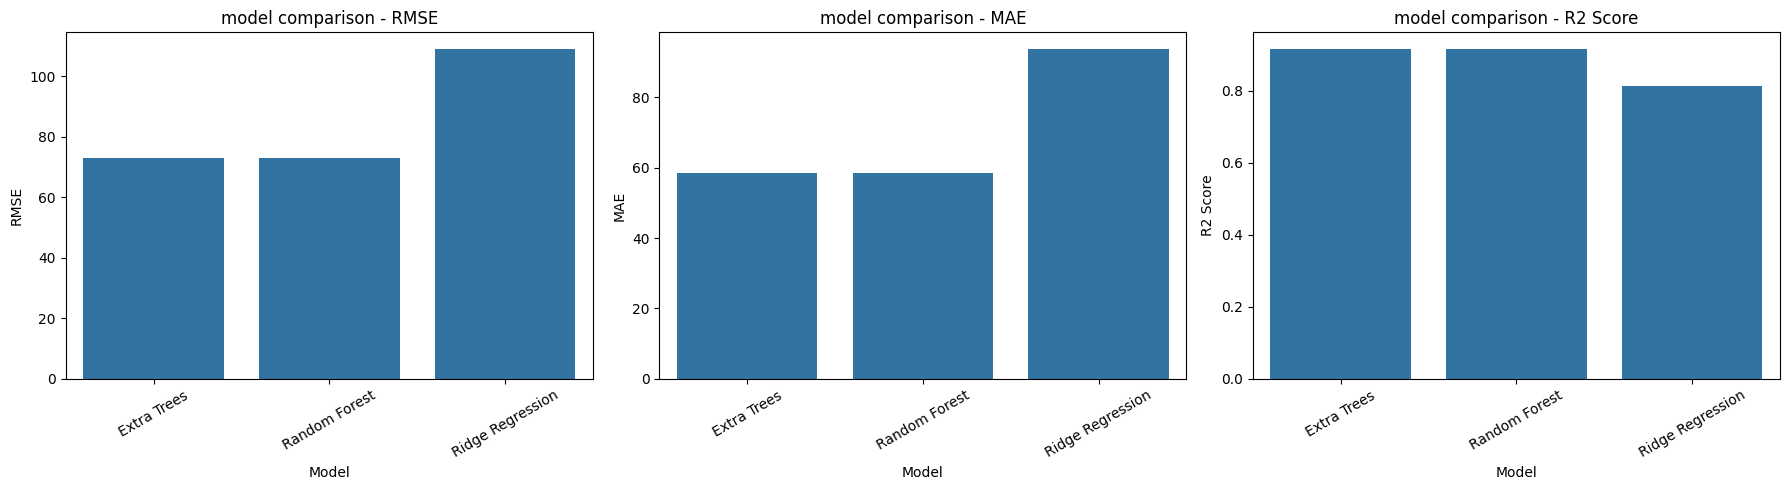

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics = ["RMSE", "MAE", "R2 Score"]

for ax, metric in zip(axes, metrics):

    sns.barplot(
        data=test_comparison_df,
        x="Model",
        y=metric,
        ax=ax
    )

    ax.set_title(f"model comparison - {metric}")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [14]:
#Residuals represent the difference between actual and predicted values.
# calculate residuals
residuals = y_test.values - test_predictions

residual_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": test_predictions,
    "Residual": residuals
})

display(residual_df.head(10))

print("mean residual:", np.mean(residuals))
print("residual standard deviation:", np.std(residuals))
print("maximum residual:", np.max(residuals))
print("minimum residual:", np.min(residuals))

,Actual,Predicted,Residual
0,598,605.869960,-7.869960
1,521,494.661118,26.338882
2,450,391.767296,58.232704
3,234,379.339216,-145.339216
4,309,464.586689,-155.586689
5,307,255.130975,51.869025
6,441,354.323487,86.676513
7,666,558.320381,107.679619
8,499,449.673278,49.326722
9,404,419.237601,-15.237601


mean residual: -0.7526498074131356
residual standard deviation: 72.94264906391328
maximum residual: 359.304889022742
minimum residual: -607.3649689754693


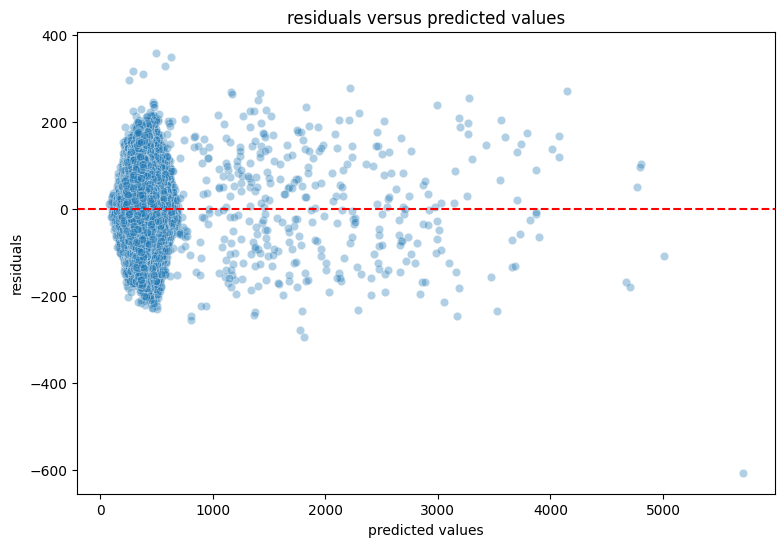

In [15]:
#Residual versus predicted plot
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=test_predictions,
    y=residuals,
    alpha=0.35
)

plt.axhline(
    y=0,
    linestyle="--",
    color="red"
)

plt.xlabel("predicted values")
plt.ylabel("residuals")
plt.title("residuals versus predicted values")

plt.show()

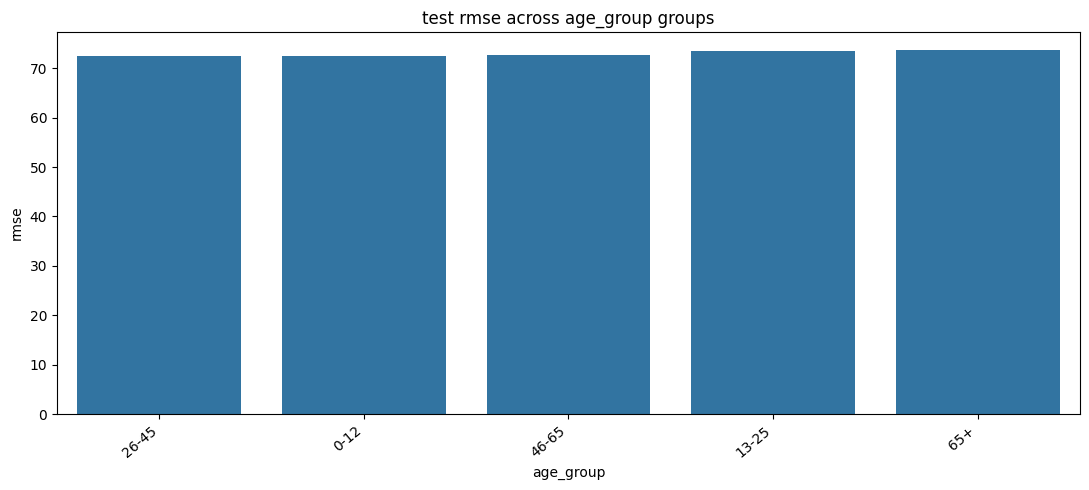

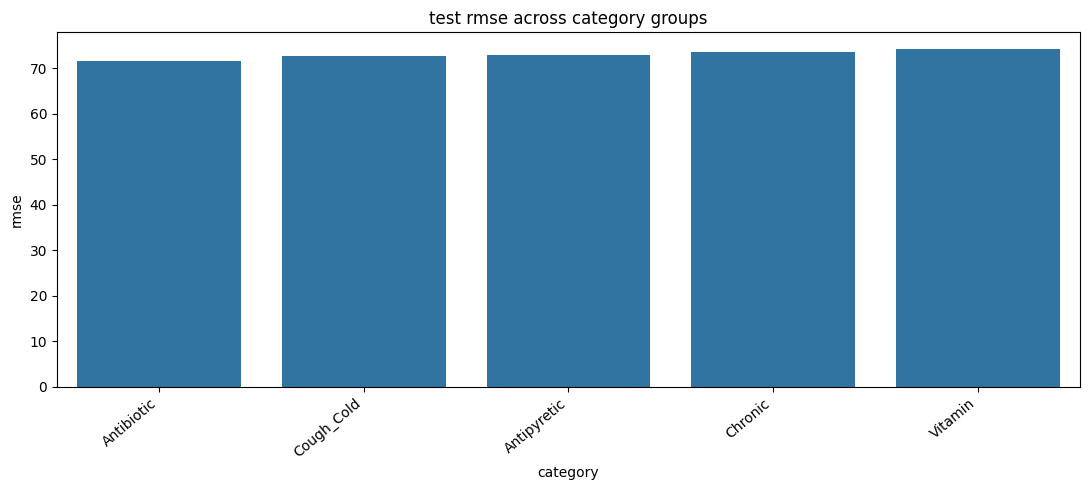

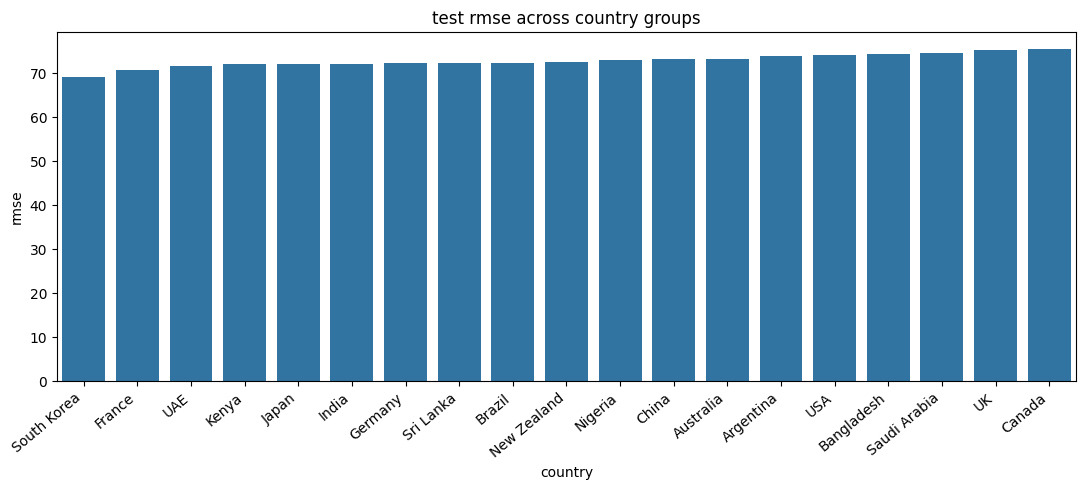

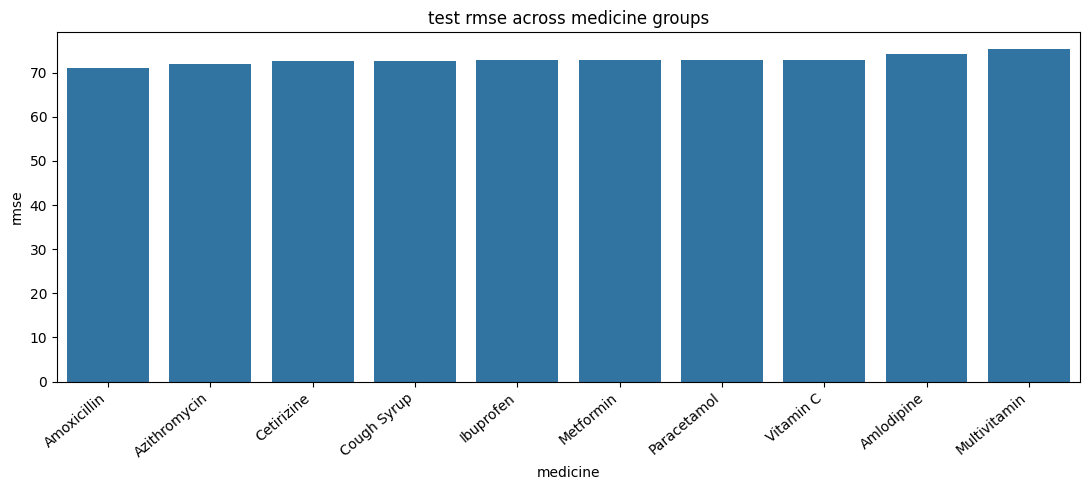

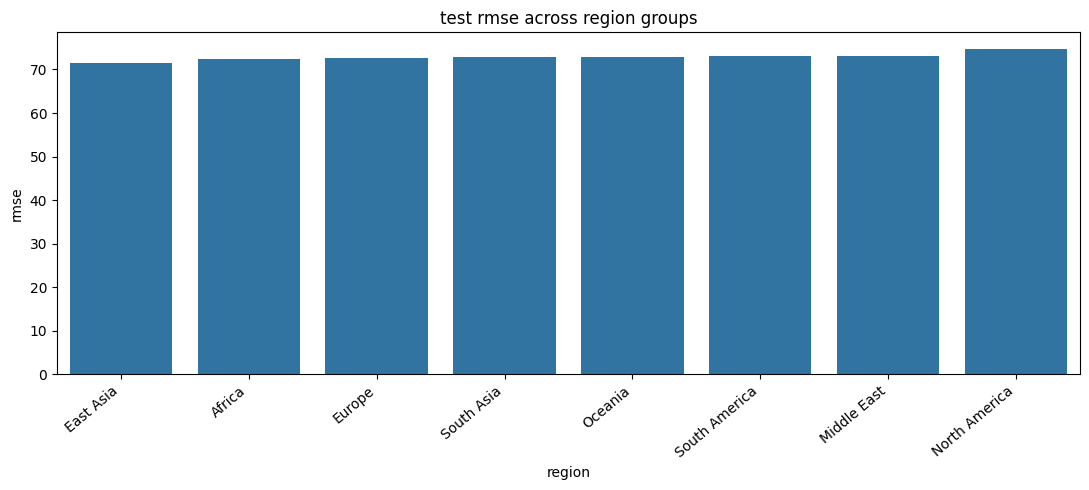

subpopulation columns evaluated: ['region', 'country', 'category', 'age_group', 'medicine']


In [17]:
#Predictive accuracy across subpopulations
# select available subpopulation columns from the dataset
candidate_group_columns = [
    "region",
    "country",
    "category",
    "age_group",
    "medicine"
]

group_columns = [
    col for col in candidate_group_columns
    if col in df.columns
]

# combine actual values, predictions, and group labels
subpopulation_data = df.loc[X_test.index, group_columns].copy()
subpopulation_data["actual"] = y_test.values
subpopulation_data["predicted"] = test_predictions
subpopulation_data["residual"] = (
    subpopulation_data["actual"] - subpopulation_data["predicted"]
)

subpopulation_results = []

# calculate regression metrics separately for each group
for group_column in group_columns:

    for group_name, group_data in subpopulation_data.groupby(
        group_column,
        dropna=False
    ):

        if len(group_data) < 30:
            continue

        group_rmse = np.sqrt(
            mean_squared_error(
                group_data["actual"],
                group_data["predicted"]
            )
        )

        group_mae = mean_absolute_error(
            group_data["actual"],
            group_data["predicted"]
        )

        group_r2 = (
            r2_score(group_data["actual"], group_data["predicted"])
            if len(group_data) >= 2
            else np.nan
        )

        subpopulation_results.append({
            "Grouping Feature": group_column,
            "Subpopulation": str(group_name),
            "Records": len(group_data),
            "RMSE": group_rmse,
            "MAE": group_mae,
            "R2 Score": group_r2,
            "Mean Residual": group_data["residual"].mean()
        })

subpopulation_df = pd.DataFrame(subpopulation_results)

if not subpopulation_df.empty:
    subpopulation_df = subpopulation_df.sort_values(
        ["Grouping Feature", "RMSE"]
    ).reset_index(drop=True)

   # display(subpopulation_df.round(4))

    # compare rmse within each grouping feature
    for group_column in subpopulation_df["Grouping Feature"].unique():

        plot_data = subpopulation_df[
            subpopulation_df["Grouping Feature"] == group_column
        ]

        plt.figure(figsize=(11, 5))
        sns.barplot(
            data=plot_data,
            x="Subpopulation",
            y="RMSE"
        )
        plt.title(f"test rmse across {group_column} groups")
        plt.xlabel(group_column)
        plt.ylabel("rmse")
        plt.xticks(rotation=40, ha="right")
        plt.tight_layout()
        plt.show()

else:
    print("no subpopulation groups had at least 30 test records")

print("subpopulation columns evaluated:", group_columns)


In [ ]:
# Final evaluation summary
# display the final held-out test metrics
final_summary = pd.DataFrame({
    "Metric": ["RMSE", "MAE", "R2 Score"],
    "Test Performance": [test_rmse, test_mae, test_r2]
})

print("selected regression model:", best_model_name)
display(final_summary.round(4))

# summarize validation coverage
print("subpopulation dimensions evaluated:", len(group_columns))
print(
    "subpopulation groups evaluated:",
    len(subpopulation_df) if not subpopulation_df.empty else 0
)

print("\nregression evaluation completed")


selected regression model: Random Forest


,Metric,Test Performance
0,RMSE,72.9465
1,MAE,58.4442
2,R2 Score,0.9163


subpopulation dimensions evaluated: 5
subpopulation groups evaluated: 47

regression evaluation completed
